## Framing

**Who uses the tool?**

A wine merchant who must choose among hundreds of bottles which ones to send to a panel of expert tasters.

**What decision?**

The model predicts from chemical measurements whether a wine is good (quality ≥ 6). Wines predicted "good" are going to be tasted first.

**Cost of a false positive (FP)**

The model says good but the wine is not then the panel wastes time on a bad wine and the cost is moderate.

**Cost of a false negative**

The model says not good but the wine is good: a good wine is never tasted and a sale is lost so we think the cost higher in this use case.

**Consequence**

We want to avoid FN more than FP because missing a good wine costs more than wasting tasting time. So we prioritize recall on good wines. We track F1 (balance of precision and recall) as our main metric, and the confusion matrix to see exactly how many FP and FN the model makes.

**Data limits**

The dataset only contains Portuguese Vinho Verde wines rated by human tasters. The model may not generalize to wines from other regions or grape varieties. Quality scores also reflect one panel’s taste, not an objective measure.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from wine_quality.data import DatasetLoader

loader = DatasetLoader("../config.yaml")
df = loader.load()

print(df.shape)
df.head()

(5320, 14)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type,good
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red,1
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,red,0


The dataset has 5,320 wines after removing duplicates (1,599 red and 4,898 white that got merged).
Each row is one wine with 11 chemical measurements. The `good` column is our target and 1 if quality ≥ 6, else would be 0.

In [2]:
print(df.shape)
print(df.dtypes)
print("Missing values:", df.isna().sum().sum())
print("Duplicates:", df.duplicated().sum())

(5320, 14)
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
wine_type                   str
good                      int64
dtype: object
Missing values: 0
Duplicates: 0


Red and white wines are merged with DatasetLoader; 1177 exact duplicates are removed (so we go from 6497 to  5320 rows).

In [3]:
df["quality"].value_counts().sort_index()

quality
3      30
4     206
5    1752
6    2323
7     856
8     148
9       5
Name: count, dtype: int64

quality
3      30
4     206
5    1752
6    2323
7     856
8     148
9       5
Name: count, dtype: int64


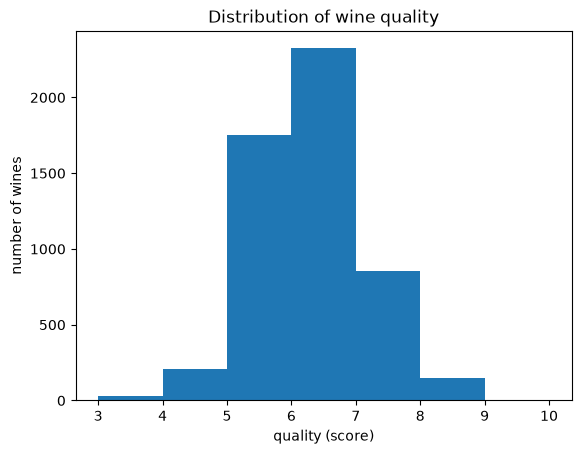

In [4]:

print(df["quality"].value_counts().sort_index())

plt.hist(df["quality"], bins=range(3, 11))
plt.title("Distribution of wine quality")
plt.xlabel("quality (score)")
plt.ylabel("number of wines")
plt.show()


Most wines are rated 5 or 6 and very few get extreme scores ( like 3 or 9).
The distribution is roughly bell-shaped around 6, which is our cutoff for "good".

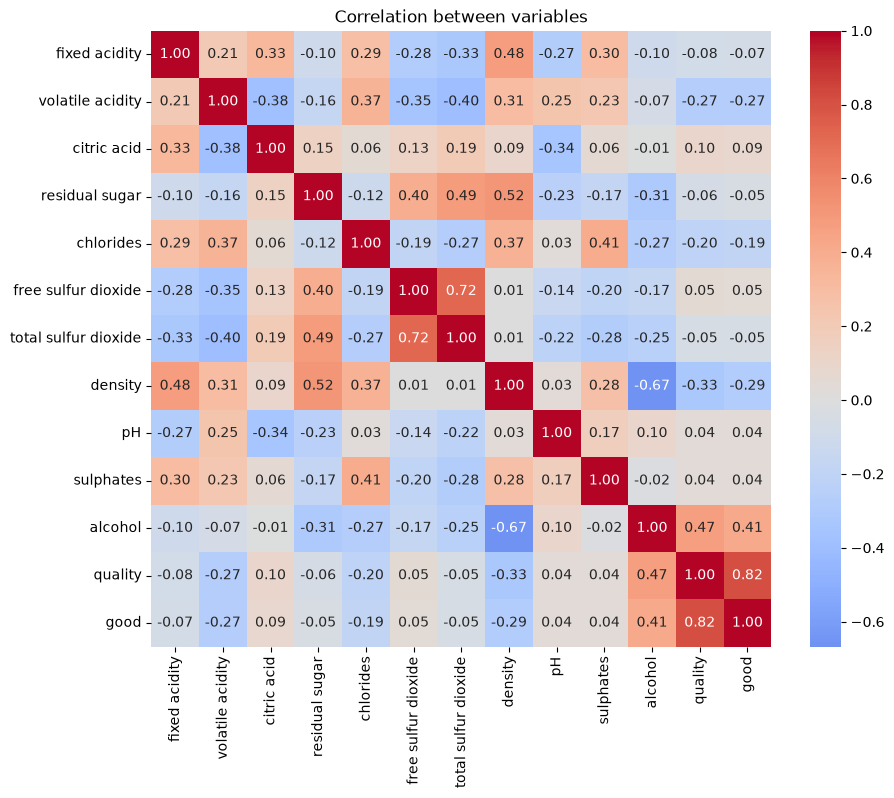

In [5]:

corr = df.drop(columns="wine_type").corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between variables")
plt.show()

Alcohol is the most correlated feature with quality (0.47) and good (0.41).
Volatile acidity is negatively correlated (-0.27) and higher acidity tends to mean lower quality.
Free and total sulfur dioxide are strongly correlated with each other (0.72) because they carry similar information.

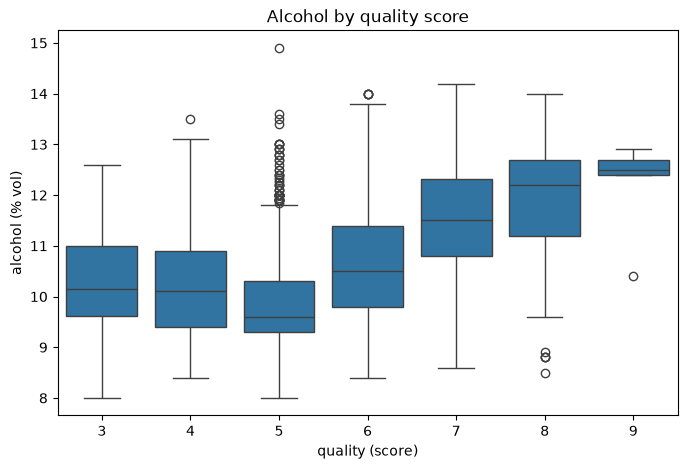

In [6]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="quality", y="alcohol")
plt.title("Alcohol by quality score")
plt.xlabel("quality (score)")
plt.ylabel("alcohol (% vol)")
plt.show()

Higher quality wines tend to have more alcohol. The median alcohol level rises clearly from quality 5 to quality 8 so this is why alcohol is the most important feature in our model.

In [7]:
print(df["good"].value_counts())
print(df["good"].value_counts(normalize=True).round(3))

good
1    3332
0    1988
Name: count, dtype: int64
good
1    0.626
0    0.374
Name: proportion, dtype: float64


good = quality ≥ 6: 62.6 % good, 37.4 % not good, moderately imbalanced.

## Model comparison


We compare four models with 5-fold cross-validation on the training set only: a dummy baseline, logistic regression, k-NN and a linear SVM. The three real models clearly beat the baseline on ROC-AUC (the dummy is at 0.50, which is pure chance), so the chemical measurements do contain useful information.

In [8]:
from wine_quality.models import Trainer

X_train, X_test, y_train, y_test = loader.split()
trainer = Trainer("../config.yaml")
trainer.compare(X_train, y_train)

,f1,roc_auc
logistic regression,0.802,0.804
linear SVM,0.802,0.804
k-NN,0.799,0.803
Dummy,0.770,0.500


The dummy baseline gets ROC-AUC = 0.50 (pure chance), confirming the real models learn something. We use F1 as our main metric because the classes are slightly imbalanced (63% good vs 37% not good).

## Tuning

We search the best hyperparameters for each model with GridSearchCV (5-fold CV, scoring = F1). The model with the highest F1 is saved as the best pipeline.

In [9]:
best_pipeline = trainer.tune(X_train, y_train)
trainer.save()

logistic regression: best params = {'clf__C': 0.1}, F1 = 0.803
k-NN: best params = {'clf__n_neighbors': 20}, F1 = 0.801
linear SVM: best params = {'clf__estimator__C': 0.01}, F1 = 0.803


WindowsPath('models/best_model.joblib')

## Decision threshold
We find the optimal decision threshold using out-of-fold predictions on the training set.
A classifier gives a probability of being a good wine. The threshold decides from which probability we label it as good (default: 0.5). We find the optimal threshold using out-of-fold predictions on the training set to avoid touching the test set


In [10]:
import numpy as np
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import cross_val_predict

oof_proba = cross_val_predict(best_pipeline, X_train, y_train, cv=5, method="predict_proba")[:, 1]
precision, recall, thresholds = precision_recall_curve(y_train, oof_proba)
f1_scores = 2 * precision * recall / (precision + recall + 1e-9)
threshold = round(float(thresholds[np.argmax(f1_scores[:-1])]), 2)
print(f"Best threshold: {threshold}")

Best threshold: 0.48


## Final evaluation on the test set

The test set is used only once, at the very end, to get an honest estimate of performance on unseen wines. The confusion matrix shows how many good and not-good wines the model correctly identifies


{'f1': 0.814, 'roc_auc': 0.814}


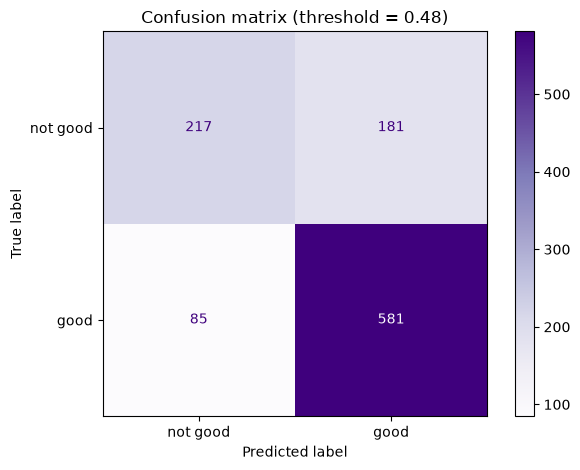

In [11]:
from wine_quality.evaluate import evaluate_test, plot_confusion_matrix

print(evaluate_test(best_pipeline, X_test, y_test, threshold))
plot_confusion_matrix(best_pipeline, X_test, y_test, threshold)

In [12]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    best_pipeline, X_test, y_test, scoring="f1",
    n_repeats=10, random_state=loader.cfg["model"]["random_state"],
)
importance = pd.Series(result.importances_mean, index=X_test.columns)
importance.sort_values(ascending=False)

alcohol                 0.065481
volatile acidity        0.051427
residual sugar          0.018870
free sulfur dioxide     0.012527
total sulfur dioxide    0.009194
sulphates               0.005782
density                 0.005583
pH                      0.005300
wine_type               0.003805
fixed acidity           0.002589
citric acid            -0.000278
chlorides              -0.000714
dtype: float64

## Interpretation

**Most important features.** The model relies mostly on alcohol, volatile acidity and residual sugar. This shows what the model uses, not what causes quality.
as in adding more alcohol doesn't make a wine better, it's just a pattern found by the model.

**Two limits.**
1. The data only contains Portuguese Vinho Verde wines rated by human tasters, so the model may not work for other wines.
2. The model is only moderately good (F1 0.81): 181 wines that are not good were called good so that means the merchant would still waste time on some bad wines.

**Ethical risks.**
The model’s definition of ‘good’ is based on scores from one tasting panel. A small producer whose style differs from what that panel prefers could be unfairly penalized. The model gives a probability but no explanation of which features caused the rejection.